### Workplace PIP Risk Prediction using Logistic Regression
#### 1. Project overview  
Goal: Predict whether an employee may require a Performance Improvement Plan (PIP).  
- pip_required = 1: PIP may be required  
- pip_required = 0: PIP may not be required  
This is a binary classification project. The model should support human review, not automatically make HR decisions.

Project workflow 
1. Load and understand the data
2. Clean duplicates and check missing values
3. Explore the data
4. Separate features and target
5. Split into training and testing data
6. Prepare the data
7. Train Logistic Regression
8. Evaluate and interpret the model

### 2. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold

#### 3. Load the dataset  
Keep the CSV file in the same folder as this notebook. Change the filename if yours is different.

In [2]:
df = pd.read_csv(r"C:\Users\riaka\Downloads\PIP_Risk_Dataset - LMS.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (6315, 26)


,employee_id,desk_zone,laptop_model,age,gender,department,job_role,job_level,employment_type,tenure_months,...,tasks_assigned_last_month,tasks_completed_last_month,overdue_tasks_count,quality_score,rework_count_last_month,client_escalations_count_3m,manager_rating,training_hours_last_3m,certifications_completed,pip_required
0,ORG01226,C,HP ProBook,26,Female,Marketing,Content Specialist,2,Full-time,93,...,36,27,3,67.4,4,0,3.0,32.1,3,0
1,ORG03879,A,Lenovo ThinkPad,31,Male,Engineering,Software Engineer,2,Full-time,67,...,42,31,4,70.0,2,1,4.0,23.2,2,0
2,ORG04879,D,Dell Latitude,29,Female,Sales,Inside Sales Rep,2,Full-time,82,...,48,33,3,38.3,3,4,1.0,12.9,0,0
3,ORG05202,A,Lenovo ThinkPad,29,Male,Engineering,Data Analyst,4,Contract,2,...,66,47,14,79.9,3,0,3.0,28.0,4,0
4,ORG01484,D,Lenovo ThinkPad,29,Female,Sales,Inside Sales Rep,3,Contract,7,...,51,42,4,71.7,2,0,3.0,13.3,4,0


#### 4. Understand the dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6315 entries, 0 to 6314
Data columns (total 26 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   employee_id                  6315 non-null   object 
 1   desk_zone                    6315 non-null   object 
 2   laptop_model                 6315 non-null   object 
 3   age                          6315 non-null   int64  
 4   gender                       6315 non-null   object 
 5   department                   6315 non-null   object 
 6   job_role                     6315 non-null   object 
 7   job_level                    6315 non-null   int64  
 8   employment_type              6315 non-null   object 
 9   tenure_months                6315 non-null   int64  
 10  attendance_percentage        6269 non-null   float64
 11  late_mark_count_30d          6315 non-null   int64  
 12  unplanned_leave_count_3m     6315 non-null   int64  
 13  policy_violation_c

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
employee_id,6315,6240,ORG02065,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
desk_zone,6315,4,D,1614,NaN,NaN,NaN,NaN,NaN,NaN,NaN
laptop_model,6315,5,Dell Latitude,1867,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,6315.0,NaN,NaN,NaN,29.0038,4.449091,21.0,26.0,29.0,32.0,46.0
gender,6315,3,Male,3610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,6315,8,Engineering,1446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_role,6315,22,Support Associate,521,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_level,6315.0,NaN,NaN,NaN,2.572288,1.04141,1.0,2.0,3.0,3.0,5.0
employment_type,6315,2,Full-time,5509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure_months,6315.0,NaN,NaN,NaN,54.148852,36.031592,1.0,19.0,52.0,86.0,120.0


**Check missing values and duplicates**

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
employee_id                     0
desk_zone                       0
laptop_model                    0
age                             0
gender                          0
department                      0
job_role                        0
job_level                       0
employment_type                 0
tenure_months                   0
attendance_percentage          46
late_mark_count_30d             0
unplanned_leave_count_3m        0
policy_violation_count_6m       0
kpi_score                      46
goal_completion_rate           41
tasks_assigned_last_month       0
tasks_completed_last_month      0
overdue_tasks_count             0
quality_score                  36
rework_count_last_month         0
client_escalations_count_3m     0
manager_rating                 45
training_hours_last_3m         43
certifications_completed        0
pip_required                    0
dtype: int64

Duplicate rows: 75


#### 5. Clean the data  
Remove exact duplicate rows. Missing values will be handled in the preprocessing step.

In [6]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Missing target values:", df["pip_required"].isnull().sum())

Shape after removing duplicates: (6240, 26)
Missing target values: 0


### 6. Explore the target variable

pip_required
0    4985
1    1255
Name: count, dtype: int64

Class percentages:
pip_required
0    79.887821
1    20.112179
Name: proportion, dtype: float64


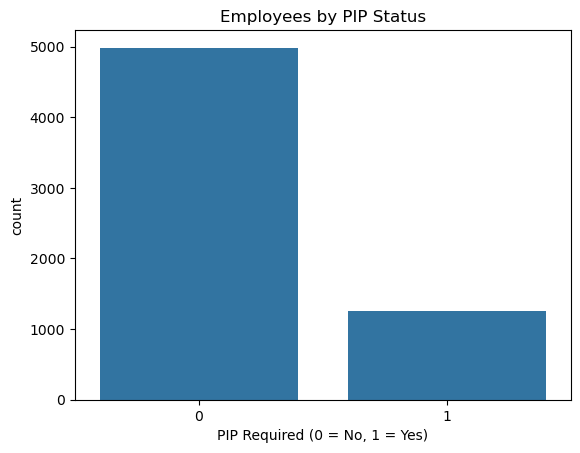

In [7]:
print(df["pip_required"].value_counts())
print("\nClass percentages:")
print(df["pip_required"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="pip_required")
plt.title("Employees by PIP Status")
plt.xlabel("PIP Required (0 = No, 1 = Yes)")
plt.show()

**Explore some numerical features**

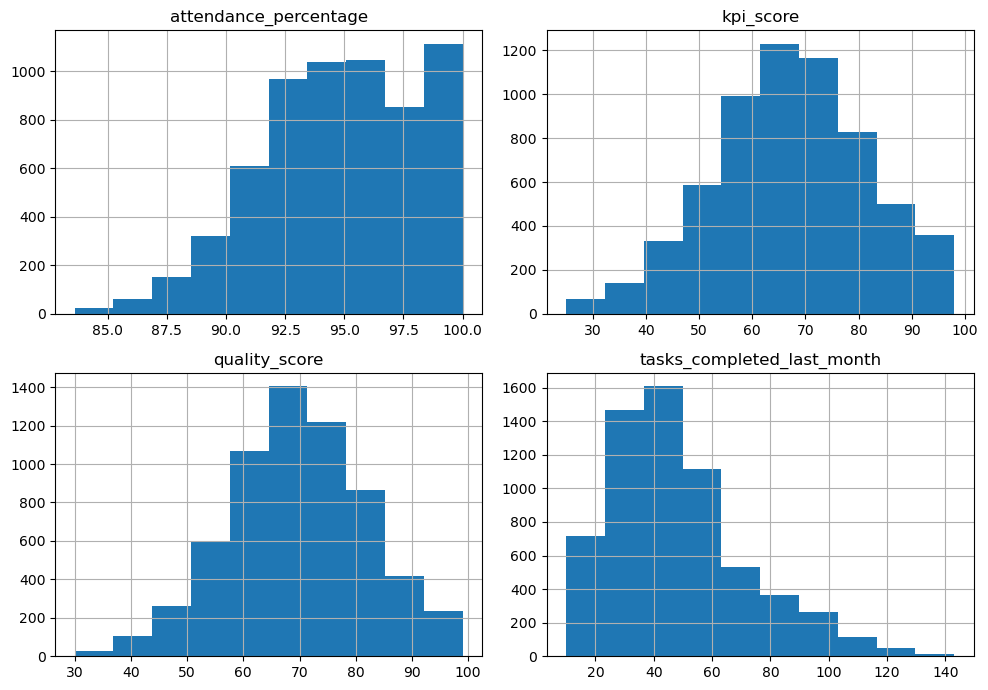

In [8]:
df[[
    "attendance_percentage",
    "kpi_score",
    "quality_score",
    "tasks_completed_last_month"
]].hist(figsize=(10, 7))

plt.tight_layout()
plt.show()

#### 7. Separate features and target  
We exclude ID and administrative columns. Age and gender are also excluded from model training; they can be reviewed separately in a fairness check.

In [9]:
target = "pip_required"

columns_to_drop = [
    "pip_required", "employee_id", "desk_zone",
    "laptop_model", "age", "gender"
]

X = df.drop(columns=columns_to_drop, errors="ignore")
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)
print(y.value_counts())

Features: (6240, 20)
Target: (6240,)
pip_required
0    4985
1    1255
Name: count, dtype: int64


#### 8. Split the data  
Use 80% for training and 20% for testing. Stratification keeps the class proportions similar in both sets.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 4992
Testing rows: 1248


#### 9. Prepare the data  
- Fill missing numerical values with the median
- Fill missing categorical values with the most common value
- Scale numerical columns
- Convert categorical columns into numbers using One-Hot Encoding

In [11]:
numeric_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns

numeric_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_steps, numeric_cols),
    ("categorical", categorical_steps, categorical_cols)
])

### 10. Train Logistic Regression  
class_weight="balanced" gives extra weight to the smaller target class.

In [12]:
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("logistic_regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


#### 11. Make predictions

In [13]:
y_pred = model.predict(X_test)

print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test.iloc[:10].values)

First 10 predictions: [0 0 1 1 0 0 1 1 0 1]
First 10 actual values: [0 0 0 0 0 0 0 0 0 0]


#### 12. Evaluate the model  
- Accuracy: Overall percentage of correct predictions
- Precision: Of predicted PIP cases, how many were actually PIP?
- Recall: Of actual PIP cases, how many did the model identify?
- F1-score: Balance between precision and recall
- ROC-AUC: How well the model separates the two classes  
Recall for class 1 matters because missing an at-risk employee may mean missing an opportunity to offer support.

In [14]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.8060897435897436
Precision: 0.5117493472584856
Recall   : 0.7808764940239044
F1-score : 0.6182965299684543

Classification report:
              precision    recall  f1-score   support

           0       0.94      0.81      0.87       997
           1       0.51      0.78      0.62       251

    accuracy                           0.81      1248
   macro avg       0.72      0.80      0.74      1248
weighted avg       0.85      0.81      0.82      1248



**Confusion matrix**

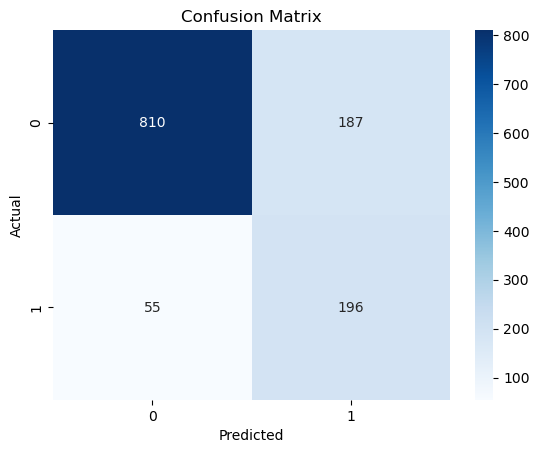

In [15]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**ROC-AUC score**

In [16]:
y_probability = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, y_probability))

ROC-AUC: 0.8824121767693519


#### 13. Understand the model  
- Positive coefficient: increases the model's predicted log-odds of class 1.  
- Negative coefficient: decreases the model's predicted log-odds of class 1.  
These are relationships learned by the model, not proof that a feature causes PIP.

In [17]:
feature_names = model.named_steps["preprocessing"].get_feature_names_out()
coefficients = model.named_steps["logistic_regression"].coef_[0]

importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance["Absolute_Coefficient"] = importance["Coefficient"].abs()
importance = importance.sort_values("Absolute_Coefficient", ascending=False)

importance[["Feature", "Coefficient"]].head(15)

,Feature,Coefficient
6,numeric__kpi_score,-0.747302
11,numeric__quality_score,-0.713325
7,numeric__goal_completion_rate,-0.360926
2,numeric__attendance_percentage,-0.358207
10,numeric__overdue_tasks_count,0.331852
33,categorical__job_role_IT Support,-0.297735
27,categorical__job_role_Content Specialist,-0.270686
47,categorical__employment_type_Contract,-0.264510
46,categorical__job_role_Talent Acquisition,-0.255765
38,categorical__job_role_Performance Marketer,0.237240


#### 14. Hyperparameter Tuning using GridSearchCV

Hyperparameter tuning is the process of finding the best settings for a machine learning model.

In this project, we use GridSearchCV to test different values of C and class_weight for Logistic Regression.

We use 5-fold Stratified Cross-Validation to evaluate the combinations while maintaining the class distribution.

Our goal is to improve the F1-score, which balances precision and recall.

In [18]:
# Parameters to test
param_grid = {
    "logistic_regression__C": [0.01, 0.1, 1, 10],
    "logistic_regression__class_weight": [None, "balanced"]
}

# 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# GridSearchCV
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

# Train and find the best settings
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'logistic_regression__C': 0.01, 'logistic_regression__class_weight': 'balanced'}
Best CV F1 Score: 0.6096810826532267


In [19]:
best_model = grid_search.best_estimator_

print("Tuned model created successfully!")

Tuned model created successfully!


In [20]:
y_pred_tuned = best_model.predict(X_test)

print("Tuned Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Tuned Precision:", precision_score(y_test, y_pred_tuned))
print("Tuned Recall:", recall_score(y_test, y_pred_tuned))
print("Tuned F1 Score:", f1_score(y_test, y_pred_tuned))

Tuned Accuracy: 0.8076923076923077
Tuned Precision: 0.5141388174807198
Tuned Recall: 0.796812749003984
Tuned F1 Score: 0.625


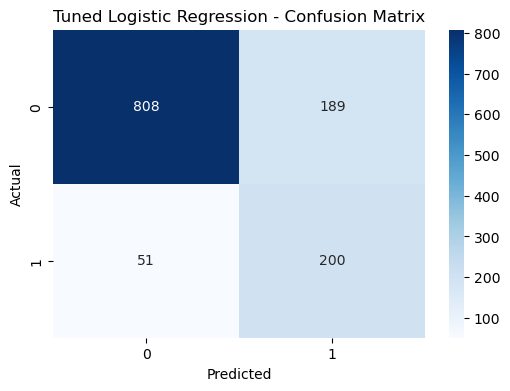

In [21]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Logistic Regression - Confusion Matrix")

plt.show()

In [22]:
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.94      0.81      0.87       997
           1       0.51      0.80      0.62       251

    accuracy                           0.81      1248
   macro avg       0.73      0.80      0.75      1248
weighted avg       0.85      0.81      0.82      1248



#### 15. Precision-Recall AUC (PR-AUC)

In [23]:
from sklearn.metrics import average_precision_score

# Predict probabilities for Class 1
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate PR-AUC (Average Precision)
pr_auc = average_precision_score(y_test, y_prob)

print("PR-AUC Score:", pr_auc)

PR-AUC Score: 0.703835280070099


#### 16. Feature Importance - Logistic Regression Coefficients

In [24]:
# Get feature names after preprocessing
feature_names = best_model.named_steps["preprocessing"].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = best_model.named_steps["logistic_regression"].coef_[0]

# Create DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
coef_df = coef_df.sort_values(
    by="Coefficient",
    ascending=False
)

print("Top 10 Features Increasing PIP Risk:")
display(coef_df.head(10))

print("Top 10 Features Decreasing PIP Risk:")
display(coef_df.tail(10))

Top 10 Features Increasing PIP Risk:


,Feature,Coefficient
10,numeric__overdue_tasks_count,0.266625
4,numeric__unplanned_leave_count_3m,0.209936
12,numeric__rework_count_last_month,0.196925
3,numeric__late_mark_count_30d,0.139686
5,numeric__policy_violation_count_6m,0.138024
13,numeric__client_escalations_count_3m,0.128918
8,numeric__tasks_assigned_last_month,0.102244
44,categorical__job_role_Support Lead,0.043927
0,numeric__job_level,0.041040
45,categorical__job_role_System Admin,0.040138


Top 10 Features Decreasing PIP Risk:


,Feature,Coefficient
9,numeric__tasks_completed_last_month,-0.034064
46,categorical__job_role_Talent Acquisition,-0.039773
33,categorical__job_role_IT Support,-0.044938
27,categorical__job_role_Content Specialist,-0.047086
15,numeric__training_hours_last_3m,-0.129097
14,numeric__manager_rating,-0.234623
2,numeric__attendance_percentage,-0.304365
7,numeric__goal_completion_rate,-0.337099
11,numeric__quality_score,-0.587837
6,numeric__kpi_score,-0.615699


#### 17. Odds Ratio Analysis

In [25]:
# Calculate Odds Ratios
coef_df["Odds_Ratio"] = np.exp(coef_df["Coefficient"])

# Display top 10 features increasing PIP odds
print("Top 10 Features Increasing PIP Odds:")
display(coef_df.sort_values(
    by="Odds_Ratio", ascending=False
).head(10))

# Display top 10 features decreasing PIP odds
print("Top 10 Features Decreasing PIP Odds:")
display(coef_df.sort_values(
    by="Odds_Ratio", ascending=True
).head(10))

Top 10 Features Increasing PIP Odds:


,Feature,Coefficient,Odds_Ratio
10,numeric__overdue_tasks_count,0.266625,1.305550
4,numeric__unplanned_leave_count_3m,0.209936,1.233600
12,numeric__rework_count_last_month,0.196925,1.217653
3,numeric__late_mark_count_30d,0.139686,1.149913
5,numeric__policy_violation_count_6m,0.138024,1.148003
13,numeric__client_escalations_count_3m,0.128918,1.137596
8,numeric__tasks_assigned_last_month,0.102244,1.107654
44,categorical__job_role_Support Lead,0.043927,1.044906
0,numeric__job_level,0.041040,1.041894
45,categorical__job_role_System Admin,0.040138,1.040954


Top 10 Features Decreasing PIP Odds:


,Feature,Coefficient,Odds_Ratio
6,numeric__kpi_score,-0.615699,0.540263
11,numeric__quality_score,-0.587837,0.555528
7,numeric__goal_completion_rate,-0.337099,0.713838
2,numeric__attendance_percentage,-0.304365,0.737592
14,numeric__manager_rating,-0.234623,0.790869
15,numeric__training_hours_last_3m,-0.129097,0.878889
27,categorical__job_role_Content Specialist,-0.047086,0.954005
33,categorical__job_role_IT Support,-0.044938,0.956057
46,categorical__job_role_Talent Acquisition,-0.039773,0.961008
9,numeric__tasks_completed_last_month,-0.034064,0.966510


#### 18. Important Features Affecting PIP Risk

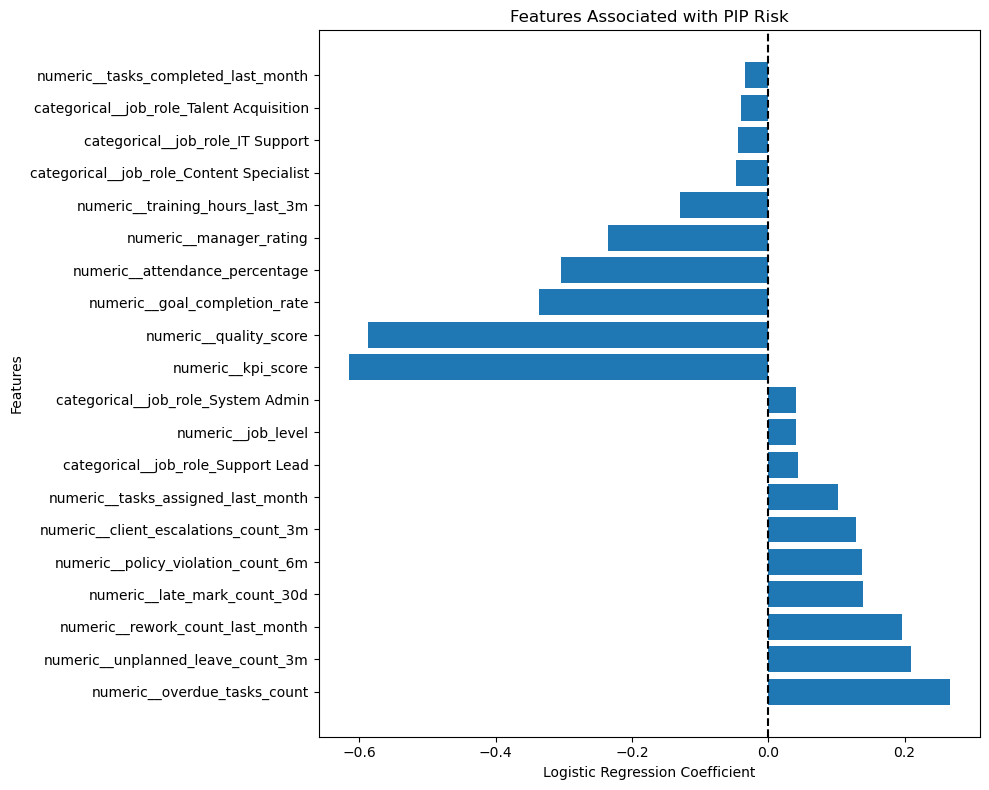

In [26]:
# Select top 10 positive and negative coefficients
top_positive = coef_df.nlargest(10, "Coefficient")
top_negative = coef_df.nsmallest(10, "Coefficient")

# Combine both
important_features = pd.concat([top_positive, top_negative])

# Plot
plt.figure(figsize=(10, 8))

plt.barh(
    important_features["Feature"],
    important_features["Coefficient"]
)

plt.axvline(x=0, color="black", linestyle="--")

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Features Associated with PIP Risk")

plt.tight_layout()
plt.show()

#### 19. Baseline vs Tuned Logistic Regression

In [27]:
# Compare both models
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"],
    "Baseline": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
        average_precision_score(y_test, model.predict_proba(X_test)[:, 1])
    ],
    "Tuned": [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_tuned),
        roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]),
        average_precision_score(y_test, best_model.predict_proba(X_test)[:, 1])
    ]
})

display(comparison.round(4))

,Metric,Baseline,Tuned
0,Accuracy,0.8061,0.8077
1,Precision,0.5117,0.5141
2,Recall,0.7809,0.7968
3,F1 Score,0.6183,0.6250
4,ROC-AUC,0.8824,0.8833
5,PR-AUC,0.7006,0.7038


## 20. Saving the Final Logistic Regression Model

In [28]:
import joblib

# Save the tuned model
joblib.dump(best_model, "pip_logistic_regression_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [29]:
# Load the saved model
loaded_model = joblib.load("pip_logistic_regression_model.pkl")

# Make predictions
sample_predictions = loaded_model.predict(X_test.head(5))

print("Sample Predictions:", sample_predictions)

Sample Predictions: [0 1 1 1 0]


## 21. Business Insights and Recommendations

Key Business Insights
1. Overdue tasks have the strongest positive coefficient among the displayed features, indicating an association with higher PIP odds.
2. Unplanned leaves and rework counts are also associated with increased PIP odds.
3. KPI score and quality score have strong negative coefficients, indicating associations with lower PIP odds.
4. Goal completion and attendance percentage are also associated with lower PIP odds.
5. The tuned Logistic Regression model achieved 79.68% recall and 62.50% F1-score for the PIP-required class.
    
Business Recommendations
- Monitor overdue tasks and provide workload-management support.
- Identify recurring rework and offer additional training.
- Review attendance patterns fairly and consider legitimate reasons for absence.
- Recognize employees with strong KPI and quality performance.
- Use model predictions as early-warning signals for human review, not automatic PIP decisions.

## 22. Project Conclusion

Copy this content into it:  
Conclusion  
In this project, Logistic Regression was used to predict whether an employee may require a Performance Improvement Plan (PIP).  

The dataset was cleaned and preprocessed, followed by exploratory data analysis, feature preparation, model training, and hyperparameter tuning using GridSearchCV.  

The tuned Logistic Regression model achieved:  
- Accuracy: 80.77%
- Precision: 51.41%
- Recall: 79.68%
- F1-score: 62.50%
- ROC-AUC: 88.33%
- PR-AUC: 70.38%  
The analysis identified overdue tasks, unplanned leaves, and rework count as features associated with higher PIP odds. KPI score, quality score, and goal completion rate were associated with lower PIP odds.  

The project demonstrates how machine learning can support early identification of potential performance concerns and help organizations provide timely employee support.  

The model should be used as a decision-support tool and not as an automated system for making employee-related decisions.

## 23. Project Limitations

1. The model's precision for the PIP-required class is relatively low.
2. The dataset may not represent every organization's workforce.
3. Logistic Regression assumes a linear relationship between predictors and log-odds.
4. Model predictions depend on the quality and completeness of input data.
5. Correlation and model coefficients do not establish causation.
6. Human review is necessary before taking any employee-related action.

In [34]:
import os

dashboard_path = r"C:\Users\riaka\Downloads\PIP_Risk_Dashboard"

model_path = os.path.join(
    dashboard_path,
    "pip_logistic_regression_model.pkl"
)

dataset_path = os.path.join(
    dashboard_path,
    "PIP_Risk_Dataset - LMS.csv"
)

print("Model Exists:", os.path.exists(model_path))
print("Dataset Exists:", os.path.exists(dataset_path))

Model Exists: True
Dataset Exists: True


In [35]:
import pandas as pd
import joblib

df = pd.read_csv(dataset_path)
loaded_model = joblib.load(model_path)

print("Dataset Shape:", df.shape)
print("Model Loaded Successfully!")

Dataset Shape: (6315, 26)
Model Loaded Successfully!


In [36]:
pip install streamlit pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
!streamlit --version

Streamlit, version 1.51.0
